Analyze Nanostring data
=======================

In this tutorial we show how we can use Squidpy and Scanpy for the analysis of Nanostring data.

In [1]:
from pathlib import Path

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

sc.logging.print_header()

scanpy==1.9.0 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.10.0 pandas==1.5.3 scikit-learn==1.2.1 statsmodels==0.13.5 python-igraph==0.10.3 pynndescent==0.5.8


Download the data, unpack and load to AnnData
---------------------------------------------

Download the data from [Nanostring FFPE Dataset](https://nanostring.com/products/cosmx-spatial-molecular-imager/ffpe-dataset/). Unpack the `.tar.gz` file.
Load the unpacked dataset into an `anndata.AnnData` object. The dataset used here consists of a non-small-cell lung cancer (NSCLC) tissue which represents the largest single-cell and sub-cellular analysis on Formalin-Fixed Paraffin-Embedded (FFPE) samples.

Comment out the following lines to download the dataset.

In [2]:
# !mkdir tutorial_data
# !mkdir tutorial_data/nanostring_data
# !wget -P tutorial_data/nanostring_data https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/Lung5_Rep2/Lung5_Rep2+SMI+Flat+data.tar.gz
# !tar -xzf tutorial_data/nanostring_data/Lung5_Rep2+SMI+Flat+data.tar.gz -C tutorial_data/nanostring_data/

In [2]:
nanostring_dir = Path().resolve() / "tutorial_data" / "nanostring_data"
sample_dir = nanostring_dir / "Lung5_Rep2" / "Lung5_Rep2-Flat_files_and_images"

adata = sq.read.nanostring(
    path=sample_dir,
    counts_file="Lung5_Rep2_exprMat_file.csv",
    meta_file="Lung5_Rep2_metadata_file.csv",
    fov_file="Lung5_Rep2_fov_positions_file.csv",
)

Calculate quality control metrics
---------------------------------

Obtain the control probes using their names prefixed with "NegPrb-".
Calculate the quality control metrics on the `anndata.AnnData` using `scanpy.pp.calculate_qc_metrics`.

In [7]:
adata.var["NegPrb"] = adata.var_names.str.startswith("NegPrb")
sc.pp.calculate_qc_metrics(adata, qc_vars=["NegPrb"], inplace=True)

In [14]:
import pandas as pd

pd.set_option("display.max_columns", None)

The percentage of unassigned "NegPrb" transcripts can be calculated from the calculated qc metrics. This can later be used to estimate false discovery rate.

In [12]:
adata.obs["total_counts_NegPrb"].sum() / adata.obs["total_counts"].sum() * 100

0.3722155201830987

Next we plot the distribution of total transcripts per cell, unique transcripts per cell and transcripts per FOV.

<AxesSubplot: title={'center': 'Transcripts per FOV'}, xlabel='total_counts', ylabel='Count'>

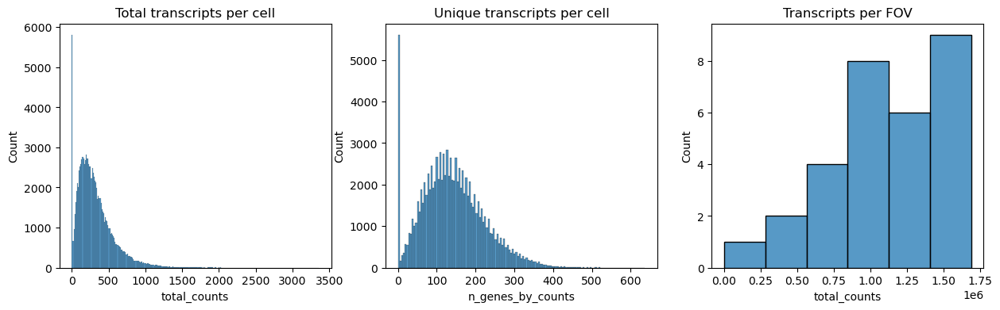

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title("Transcripts per FOV")
sns.histplot(
    adata.obs.groupby("fov").sum()["total_counts"],
    kde=False,
    ax=axs[2],
)

The dataset also contains immunofluorescence data. It can be read from adata.obs

<AxesSubplot: title={'center': 'CD3'}, xlabel='Mean.CD3', ylabel='Count'>

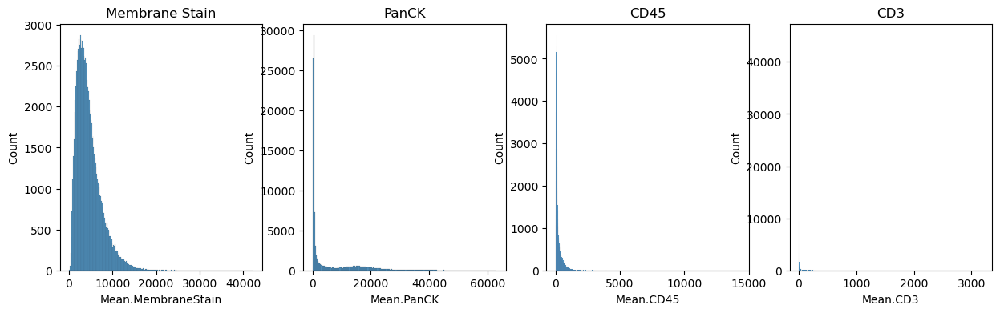

In [22]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Membrane Stain")
sns.histplot(
    adata.obs["Mean.MembraneStain"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("PanCK")
sns.histplot(
    adata.obs["Mean.PanCK"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title("CD45")
sns.histplot(
    adata.obs["Mean.CD45"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("CD3")
sns.histplot(
    adata.obs["Mean.CD3"],
    kde=False,
    ax=axs[3],
)

Filter the cells based on the minimum number of counts required using `scanpy.pp.filter_cells`. Filter the genes based on the minimum number of cells required with `scanpy.pp.filter_genes`. The parameters for both were specified based on the plots above. This filtering is quite conservative, more relaxed settings might also be applicable.
Other criteria for filtering cells could be area, immunofluorescence signal or number of unique transcripts.

In [6]:
sc.pp.filter_cells(adata, min_counts=100)
sc.pp.filter_genes(adata, min_cells=400)

Normalize counts per cell using `scanpy.pp.normalize_total`.

Logarithmize, do principal component analysis, compute a neighborhood graph of the observations using `scanpy.pp.log1p`, `scanpy.pp.pca` and `scanpy.pp.neighbors` respectively.

Use `scanpy.tl.umap` to embed the neighborhood graph of the data and cluster the cells into subgroups employing `scanpy.tl.leiden`.

You may have to install `scikit-misc` package for highly variable genes identification.

In [8]:
# !pip install scikit-misc

In [9]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata)

Visualize annotation on UMAP and spatial coordinates
----------------------------------------------------

Subplot with scatter plot in UMAP (Uniform Manifold Approximation and Projection) basis. The embedded points were colored, respectively, according to the total counts, number of genes by counts and leiden clusters in each of the subplots. This gives us some idea of what the data looks like.

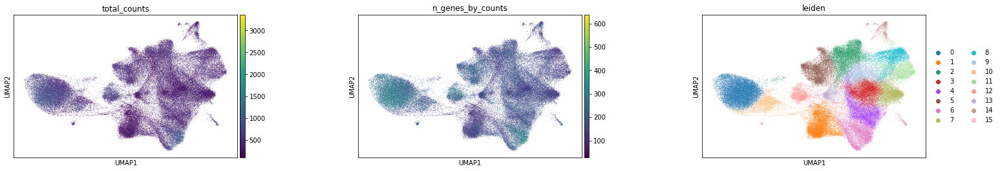

In [10]:
sc.pl.umap(
    adata,
    color=[
        "total_counts",
        "n_genes_by_counts",
        "leiden",
    ],
    wspace=0.4,
)

Plot segmentation masks using `squidpy.pl.spatial_segment`. Specifically, the key `library_id` in `adata.obs` contains the same unique values contained in `adata.uns["spatial"]`. The `"cell_ID"` column is used to spot individual cells. Here, the images were colored in accordance with the intensity of the maximum pan-cytokeratin (CK) staining.

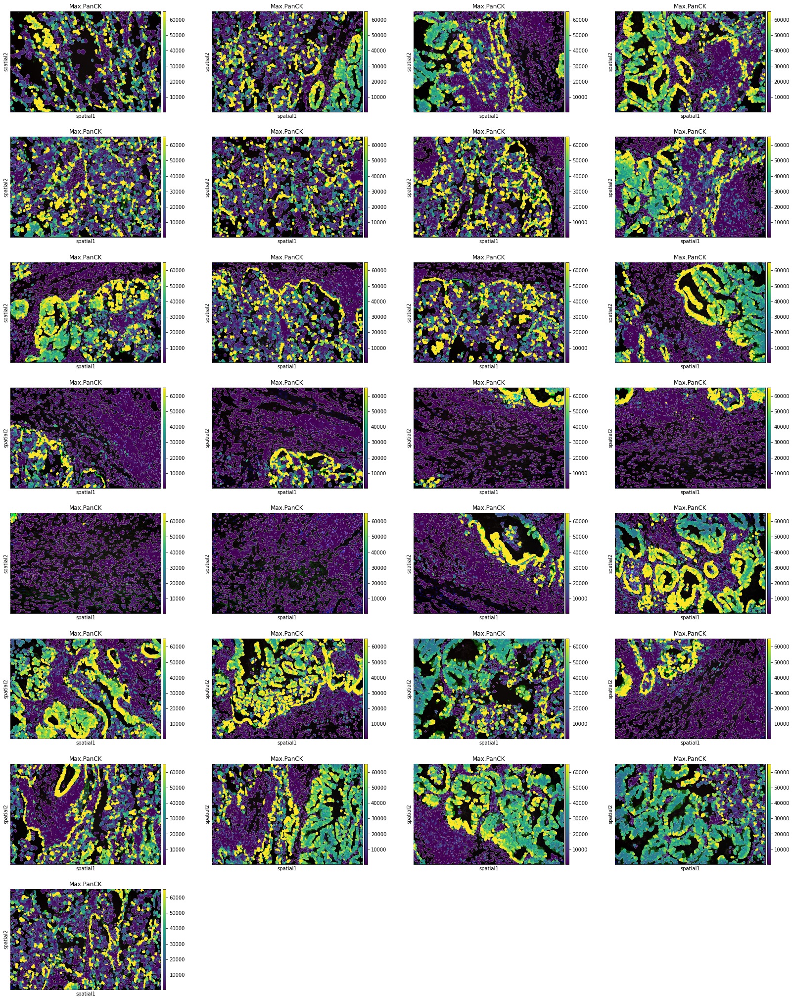

In [12]:
sq.pl.spatial_segment(
    adata,
    color="Max.PanCK",
    library_key="fov",
    seg_cell_id="cell_ID",
)

The argument `library_id` can also be altered to obtain specific field(s) of view.

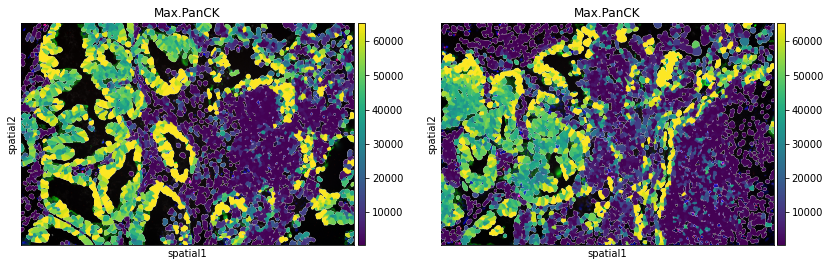

In [13]:
sq.pl.spatial_segment(
    adata,
    color="Max.PanCK",
    library_key="fov",
    library_id=["12", "16"],
    seg_cell_id="cell_ID",
)

There are several parameters that can be controlled. For instance, it is possible to plot segmentation masks as "contours", in order to visualize the underlying image.
The co-ordinates of the FOV can be specified using the argument `crop_coord`, to get the view of required section.

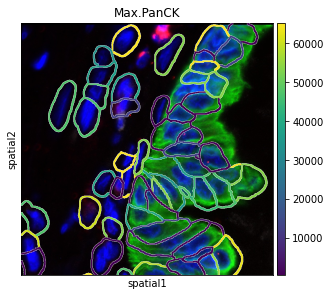

In [14]:
sq.pl.spatial_segment(
    adata,
    color="Max.PanCK",
    library_key="fov",
    library_id="12",
    seg_cell_id="cell_ID",
    seg_contourpx=10,
    crop_coord=[(0, 0, 700, 700)],
)

If groups of observations are plotted (as above), it\'s possible to modify whether to "visualize" the segmentation masks that do not belong to any selected group. It is set as \"transparent\" by default (see above) but in cases where e.g. no image is present it can be useful to visualize them nonetheless.

A scale bar can also be added, where size and pixel units must be passed. The sizes of the scalebars for these examples are not real values and are purely for visualization purposes.

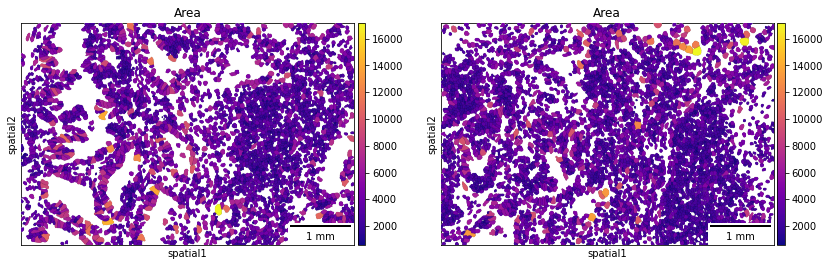

In [15]:
sq.pl.spatial_segment(
    adata,
    color="Area",
    library_key="fov",
    library_id=["12", "16"],
    seg_cell_id="cell_ID",
    seg_outline=True,
    cmap="plasma",
    img=False,
    scalebar_dx=1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
)

Plot the image, with an overlay of the Leiden clusters. Use `squidpy.pl.spatial_segment` for the same. The image is not visualized by specifying `img=False`.

One or multiple groups can also be used to overlay, by specifying the `groups` argument in `squidpy.pl.spatial_segment` as shown in the second subplot.

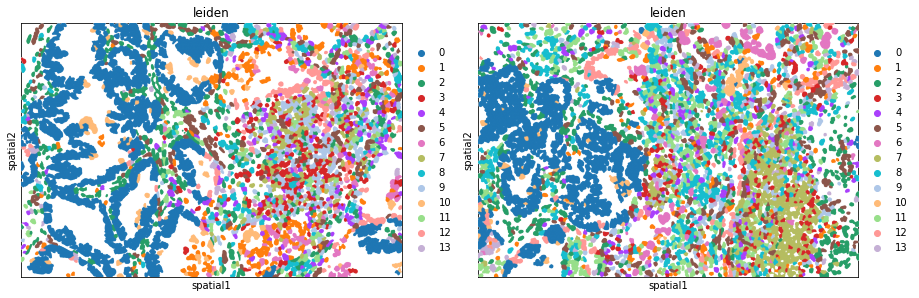

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
sq.pl.spatial_segment(
    adata,
    shape="hex",
    color="leiden",
    library_key="fov",
    library_id="12",
    seg_cell_id="cell_ID",
    img=False,
    size=60,
    ax=ax[0],
)

sq.pl.spatial_segment(
    adata,
    color="leiden",
    seg_cell_id="cell_ID",
    library_key="fov",
    library_id="16",
    img=False,
    size=60,
    ax=ax[1],
)

----

Computation of spatial statistics
---------------------------------

Building the spatial neighbors graphs
-------------------------------------

Spatial graph is a graph of spatial neighbors with observations as nodes and neighborhood relations between observations as edges. We use spatial coordinates of spots/cells to identify neighbors among them. Different approaches of defining a neighborhood relation among observations are used for different types of spatial datasets. We use `squidpy.gr.spatial_neighbors` to compute the spatial neighbors graph. We use this function for a non-grid dataset with `coord_type = 'generic'`.

Depending on the `coord_type`, `n_neighs` specifies the number of neighboring tiles if `coord_type='grid'` and when the `coord_type` is not a grid, `n_neighs` represents the number of neighborhoods. Moreover, `radius` is only available when `coord_type='generic'`.

Alternatively, `delaunay = True` can be used, for a Delaunay triangulation graph. This way, we can observe the difference in using K-nearest neighbors and Delaunay triangulation. You can appreciate that the neighbor graph is different than before.

/Users/giovanni.palla/Projects/anndata/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value
/Users/giovanni.palla/Projects/anndata/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


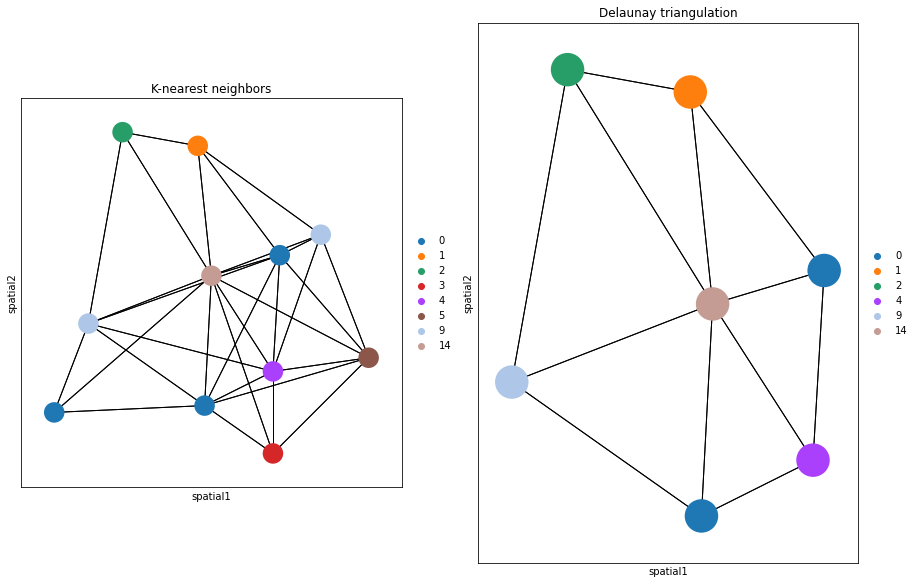

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 15))
sq.gr.spatial_neighbors(
    adata,
    n_neighs=10,
    coord_type="generic",
)
_, idx = adata.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    adata[idx, :],
    library_id="16",
    color="leiden",
    connectivity_key="spatial_connectivities",
    size=3,
    edges_width=1,
    edges_color="black",
    img=False,
    title="K-nearest neighbors",
    ax=ax[0],
)

sq.gr.spatial_neighbors(
    adata,
    n_neighs=10,
    coord_type="generic",
    delaunay=True,
)
_, idx = adata.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    adata[idx, :],
    library_id="16",
    color="leiden",
    connectivity_key="spatial_connectivities",
    size=3,
    edges_width=1,
    edges_color="black",
    img=False,
    title="Delaunay triangulation",
    ax=ax[1],
)

The function builds a spatial graph and saves its adjacency matrix `adata.obsp['spatial_connectivities']` and distances to `adata.obsp['spatial_distances']` by default.

In [22]:
adata.obsp["spatial_connectivities"]

<89246x89246 sparse matrix of type '<class 'numpy.float64'>'
	with 534344 stored elements in Compressed Sparse Row format>

In [23]:
adata.obsp["spatial_distances"]

<89246x89246 sparse matrix of type '<class 'numpy.float64'>'
	with 534344 stored elements in Compressed Sparse Row format>

In order to get all spots within a specified radius (in units of the spatial coordinates) from each spot as neighbors, the parameter `radius` should be used. We can observe how this plot is unlike the above one.

/Users/giovanni.palla/Projects/anndata/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


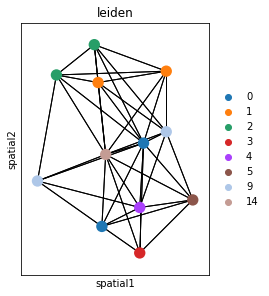

In [24]:
sq.gr.spatial_neighbors(
    adata,
    radius=30,
    coord_type="generic",
)

_, idx = adata.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    adata[idx, :],
    library_id="16",
    color="leiden",
    connectivity_key="spatial_connectivities",
    size=3,
    edges_width=1,
    edges_color="black",
    img=False,
)

In [25]:
adata.obsp["spatial_connectivities"]
adata.obsp["spatial_distances"]

<89246x89246 sparse matrix of type '<class 'numpy.float64'>'
	with 1101570 stored elements in Compressed Sparse Row format>

----

Compute centrality scores
-------------------------

This example shows how to compute centrality scores, given a spatial graph and cell type annotation.

The scores calculated are closeness centrality, degree centrality and clustering coefficient with the following properties:
* closeness centrality - measure of how close the group is to other nodes.
* clustering coefficient - measure of the degree to which nodes cluster together.
* degree centrality - fraction of non-group members connected to group members.

All scores are descriptive statistics of the spatial graph.

This dataset contains Leiden cluster groups' annotations in `anndata.AnnData.obs`, which are used for calculation of centrality scores.

First, we need to compute a connectivity matrix from spatial coordinates to calculate the centrality scores. We can use `squidpy.gr.spatial_neighbors` for this purpose. We use the `coord_type="generic"` based on the data and the neighbors are classified with Delaunay triangulation by specifying `delaunay=True`.

In [26]:
adata_spatial_neighbor = sq.gr.spatial_neighbors(
    adata, coord_type="generic", delaunay=True
)

Centrality scores are calculated with `squidpy.gr.centrality_scores`, with the Leiden clusters.

In [27]:
sq.gr.centrality_scores(adata, cluster_key="leiden")

The results were visualized by plotting the average centrality, closeness centrality, and degree centrality using `squidpy.pl.centrality_scores`.

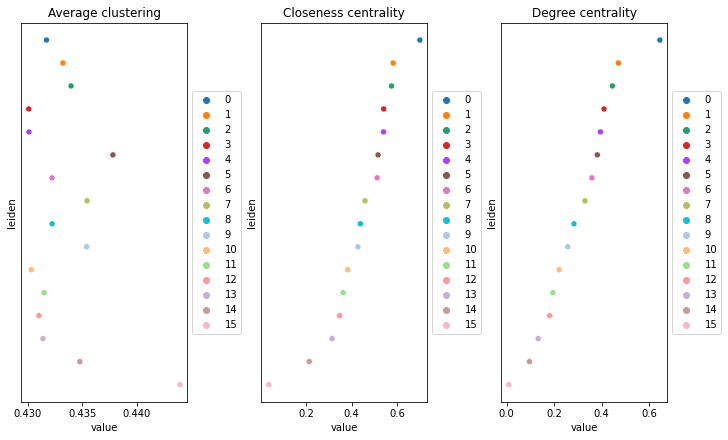

In [28]:
sq.pl.centrality_scores(adata, cluster_key="leiden", figsize=(10, 6))

----

Compute co-occurrence probability
---------------------------------

This example shows how to compute the co-occurrence probability.

The co-occurrence score is defined as:

\begin{equation}
\frac{p(exp|cond)}{p(exp)}
\end{equation}
where $p(exp|cond)$ is the conditional probability of observing a
cluster $exp$ conditioned on the presence of a cluster $cond$, whereas
$p(exp)$ is the probability of observing $exp$ in the radius size of
interest. The score is computed across increasing radii size around each
cell in the tissue.

We can compute the co-occurrence score with `squidpy.gr.co_occurrence`.
Results of co-occurrence probability ratio can be visualized with `squidpy.pl.co_occurrence`. The '3' in the $\frac{p(exp|cond)}{p(exp)}$ represents a Leiden clustered group.

In [29]:
adata_subset = adata[adata.obs.fov == "16"].copy()

We can further visualize tissue organization in spatial coordinates with `squidpy.pl.spatial_segment`, with an overlay of the expressed genes which were colored in consonance with the Leiden clusters.

100%|████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.68s/]


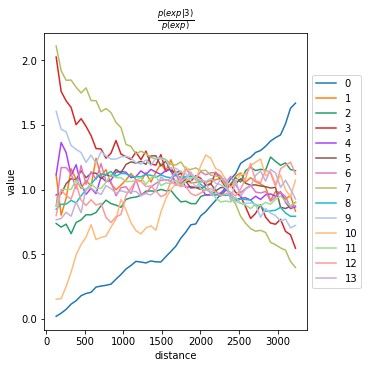

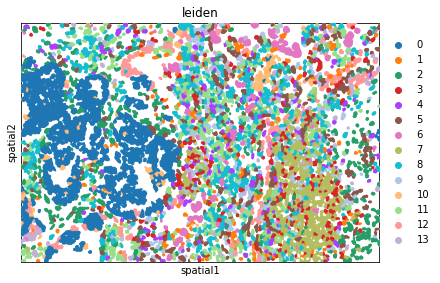

In [30]:
sq.gr.co_occurrence(
    adata_subset,
    cluster_key="leiden",
)
sq.pl.co_occurrence(
    adata_subset,
    cluster_key="leiden",
    clusters="3",
)


sq.pl.spatial_segment(
    adata_subset,
    shape="hex",
    color="leiden",
    library_id="16",
    library_key="fov",
    seg_cell_id="cell_ID",
    img=False,
    size=60,
)

----

Neighbors enrichment analysis
-----------------------------

This example shows how to run the neighbors enrichment analysis routine.

It calculates an enrichment score based on proximity on the connectivity graph of cell clusters. The number of observed events is compared against $N$ permutations and a *z-score* is computed.


This dataset contains cell type annotations in `anndata.Anndata.obs` which are used for calculation of the neighborhood enrichment. We calculate the neighborhood enrichment score with `squidpy.gr.nhood_enrichment`.

In [31]:
sq.gr.nhood_enrichment(adata, cluster_key="leiden")

100%|██████████████████████████████████████████| 1000/1000 [00:15<00:00, 64.85/s]


The same can be done for a specific FOV, by creating a subset of the `anndata.AnnData`.

In [32]:
sq.gr.nhood_enrichment(adata_subset, cluster_key="leiden")

100%|█████████████████████████████████████████| 1000/1000 [00:08<00:00, 123.89/s]


And visualize the results with `squidpy.pl.nhood_enrichment`.

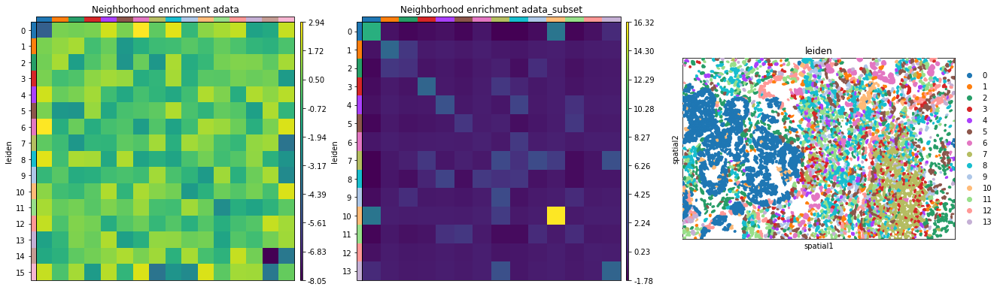

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(22, 22))
sq.pl.nhood_enrichment(
    adata,
    cluster_key="leiden",
    figsize=(3, 3),
    ax=ax[0],
    title="Neighborhood enrichment adata",
)
sq.pl.nhood_enrichment(
    adata_subset,
    cluster_key="leiden",
    figsize=(3, 3),
    ax=ax[1],
    title="Neighborhood enrichment adata_subset",
)
sq.pl.spatial_segment(
    adata_subset,
    shape="hex",
    color="leiden",
    library_id="16",
    library_key="fov",
    seg_cell_id="cell_ID",
    img=False,
    size=60,
    ax=ax[2],
)

----

Compute Ripley's statistics
---------------------------

This example shows how to compute the Ripley's L function.

The Ripley's L function is a descriptive statistics generally used to determine whether points have a random, dispersed or clustered distribution pattern at certain scale. The Ripley's L is a variance-normalized version of the Ripley's K statistic. There are also 2 other Ripley's statistics available (that are closely related): 'G' and 'F'.

Ripley's G monitors the portion of points for which the nearest neighbor is within a given distance threshold, and plots that cumulative percentage against the increasing distance radii.

For increasing separation range, Ripley's F function assembles the percentage of points which can be found in the aforementioned range from an arbitrary point pattern spawned in the expanse of the noticed pattern. 

We can compute the Ripley's L function with `squidpy.gr.ripley`.
Results can be visualized with `squidpy.pl.ripley`. The same was plotted for `adata_subset`. Other Ripley's statistics can be specified using `mode = 'G'` or `mode = 'F'`.

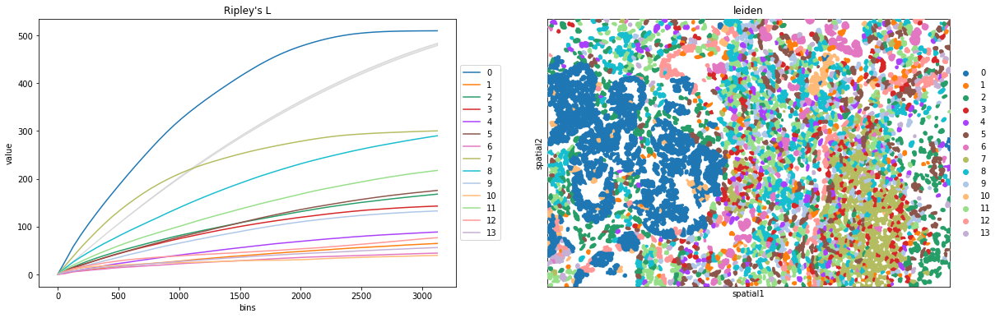

In [34]:
mode = "L"
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

sq.gr.ripley(adata_subset, cluster_key="leiden", mode=mode)
sq.pl.ripley(
    adata_subset,
    cluster_key="leiden",
    mode=mode,
    ax=ax[0],
)

sq.pl.spatial_segment(
    adata_subset,
    shape="hex",
    color="leiden",
    library_id="16",
    library_key="fov",
    seg_cell_id="cell_ID",
    img=False,
    size=60,
    ax=ax[1],
)

----

Compute Moran's I score
-----------------------

This example shows how to compute the Moran's I global spatial auto-correlation statistics.

The Moran's I global spatial auto-correlation statistics evaluates whether features (i.e. genes) shows a pattern that is clustered, dispersed or random in the tissue are under consideration.

We can compute the Moran's I score with `squidpy.gr.spatial_autocorr` and `mode = 'moran'`. We first need to compute a spatial graph with `squidpy.gr.spatial_neighbors`. We will also subset the number of genes to evaluate.

In [42]:
sq.gr.spatial_neighbors(adata_subset, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(
    adata_subset,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)
adata_subset.uns["moranI"].head(10)

100%|██████████| 100/100 [04:26<00:00,  2.67s/]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
KRT19,0.774879,0.0,0.000076,0.0,0.009901,0.000193,0.0,0.0,0.01929
OLFM4,0.752305,0.0,0.000076,0.0,0.009901,0.000204,0.0,0.0,0.01929
CEACAM6,0.749981,0.0,0.000076,0.0,0.009901,0.000179,0.0,0.0,0.01929
KRT17,0.665890,0.0,0.000076,0.0,0.009901,0.000172,0.0,0.0,0.01929
S100A6,0.624956,0.0,0.000076,0.0,0.009901,0.000132,0.0,0.0,0.01929
TM4SF1,0.586031,0.0,0.000076,0.0,0.009901,0.000196,0.0,0.0,0.01929
EPCAM,0.556131,0.0,0.000076,0.0,0.009901,0.000171,0.0,0.0,0.01929
KRT8,0.528026,0.0,0.000076,0.0,0.009901,0.000132,0.0,0.0,0.01929
ANXA2,0.511835,0.0,0.000076,0.0,0.009901,0.000163,0.0,0.0,0.01929
PIGR,0.498941,0.0,0.000076,0.0,0.009901,0.000155,0.0,0.0,0.01929


We can visualize some of those genes with `squidpy.pl.spatial_segment`. We could also pass `mode = 'geary'` to compute a closely related auto-correlation statistic, [Geary's C](https://en.wikipedia.org/wiki/Geary%27s_C). See `squidpy.gr.spatial_autocorr` for more information.

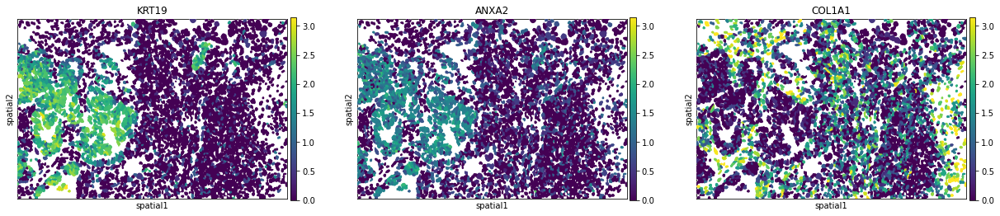

In [43]:
sq.pl.spatial_segment(
    adata_subset,
    library_id="16",
    seg_cell_id="cell_ID",
    library_key="fov",
    color=["KRT19", "ANXA2", "COL1A1"],
    size=60,
    img=False,
)